In [1]:
!pip install numpy scipy casadi pyserial matplotlib pyserial
print('OK')

OK



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Cargando telemetría real...
Entrenando EDMD offline para obtener A y B...
Gráfica guardada. Demuestra que L=0 mantiene un sesgo y no corrige el error.


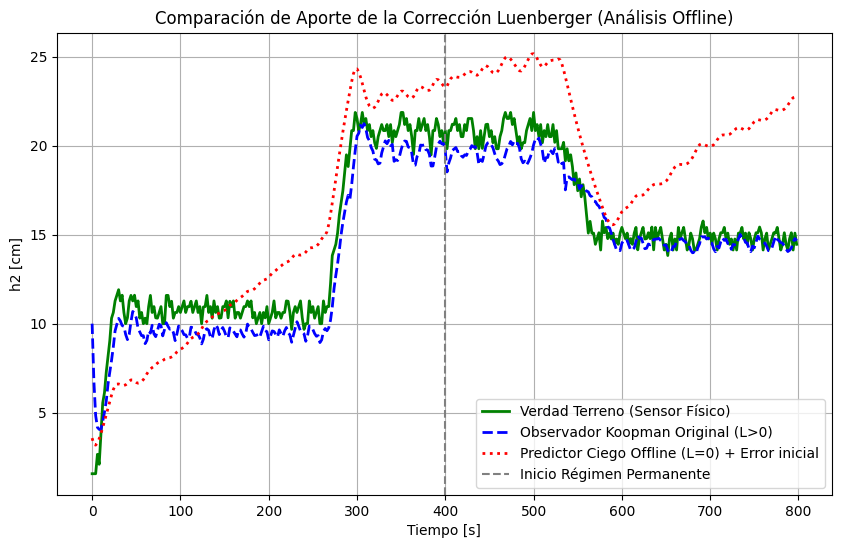

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import warnings

warnings.filterwarnings('ignore')

# --- PARÁMETROS Y FUNCIONES DE koopman_ultimo.ipynb ---
P_NOM = {
    'Atank'   : 3.02e-3, 'rho'     : 997.0, 'eta'     : 8.9e-4, 'g'       : 9.81,
    'alphao1' : 0.0271, 'Do1': 10e-3, 'alphao2' : 0.0271, 'A2' : 7.85e-5, 'alphao3' : 0.0271, 'Do3': 10e-3,
    'alpha120': 0.3038, 'D12': 10e-3, 'A12': 7.85e-5, 'lambdac12': 24000,
    'alpha230': 0.1344, 'D23': 10e-3, 'A23': 7.85e-5, 'lambdac23': 29600,
    'qi1max'  : 2.69e-5, 'qi3max'  : 2.41e-5,
}

Ts = 2.0
EPS = 1e-10
EPS_PSI = 1e-8

def nl_ode(x, u, p=P_NOM):
    h1 = max(x[0], EPS); h2 = max(x[1], EPS); h3 = max(x[2], EPS)
    qi1 = p['qi1max'] * np.clip(u[0], 0, 1)
    qi3 = p['qi3max'] * np.clip(u[1], 0, 1)
    qo1 = p['alphao1'] * (p['Do1']**2 * np.pi / 4) * np.sqrt(2 * p['g'] * h1)
    qo2 = p['alphao2'] * p['A2']                    * np.sqrt(2 * p['g'] * h2)
    qo3 = p['alphao3'] * (p['Do3']**2 * np.pi / 4) * np.sqrt(2 * p['g'] * h3)
    dh12 = h1 - h2
    l12  = p['D12'] * p['rho'] / p['eta'] * np.sqrt(2 * p['g'] * abs(dh12) + EPS)
    a12  = p['alpha120'] * np.tanh(2 * l12 / p['lambdac12'])
    q12  = a12 * p['A12'] * np.sqrt(2 * p['g'] * abs(dh12) + EPS) * np.sign(dh12 + 1e-15)
    dh23 = h2 - h3
    l23  = p['D23'] * p['rho'] / p['eta'] * np.sqrt(2 * p['g'] * abs(dh23) + EPS)
    a23  = p['alpha230'] * np.tanh(2 * l23 / p['lambdac23'])
    q23  = a23 * p['A23'] * np.sqrt(2 * p['g'] * abs(dh23) + EPS) * np.sign(dh23 + 1e-15)
    return np.array([
        (qi1 - q12 - qo1) / p['Atank'],
        (q12 - q23 - qo2) / p['Atank'],
        (qi3 + q23 - qo3) / p['Atank'],
    ])

def rk4(x, u, p=P_NOM, dt=Ts):
    k1 = nl_ode(x, u, p); k2 = nl_ode(x + dt/2*k1, u, p)
    k3 = nl_ode(x + dt/2*k2, u, p); k4 = nl_ode(x + dt*k3, u, p)
    return np.clip(x + dt/6*(k1 + 2*k2 + 2*k3 + k4), 0, 0.27)

def psi(x):
    h1, h2, h3 = x[0], x[1], x[2]
    return np.array([
        np.sqrt(max(h1, EPS_PSI)), np.sqrt(max(h2, EPS_PSI)), np.sqrt(max(h3, EPS_PSI)),
        h1 * h2, h2 * h3, h1 * h3, h1, h3,
    ], dtype=float)

def compute_ss(h2_ref, p=P_NOM):
    w_reg = 0.05
    def eqs(v):
        h1, h3, u1, u3 = v
        f = nl_ode([max(h1, 1e-4), h2_ref, max(h3, 1e-4)],
                   [np.clip(u1, 0, 1), np.clip(u3, 0, 1)], p)
        return np.concatenate([f, [w_reg * u3]])
    guesses = [
        (h2_ref*1.4, h2_ref*0.8, 0.5, 0.0), (h2_ref*1.6, h2_ref*0.7, 0.7, 0.0),
        (h2_ref*2.0, h2_ref*0.8, 0.9, 0.0), (h2_ref*2.5, h2_ref*0.8, 0.7, 0.0),
        (h2_ref*2.5, h2_ref*0.8, 0.75, 0.0),(h2_ref*1.8, h2_ref*0.85, 0.85, 0.0),
        (h2_ref*1.3, h2_ref*0.9, 1.0, 0.1), (h2_ref*1.2, h2_ref*1.0, 1.0, 0.3),
        (h2_ref*1.1, h2_ref*1.1, 1.0, 0.5), (h2_ref*1.0, h2_ref*1.2, 1.0, 0.8),
    ]
    best, best_res = None, 1e10
    for g in guesses:
        try:
            s = least_squares(eqs, list(g),
                              bounds=([0.01, 0.01, 0.0, 0.0], [0.27, 0.27, 1.0, 1.0]),
                              max_nfev=5000)
            phys_res = np.linalg.norm(s.fun[:3])
            if s.success and phys_res < best_res:
                best_res = phys_res; best = s.x
        except: pass
    if best is not None and best_res < 1e-4:
        return (np.array([best[0], h2_ref, best[1]]),
                np.array([np.clip(best[2], 0, 1), np.clip(best[3], 0, 1)]))
    return None, None

def train_edmd(verbose=True):
    rng = np.random.default_rng(42)
    z_k, u_k, z_k1 = [], [], []
    for h2r in [0.10, 0.12, 0.15, 0.18, 0.20, 0.22]:
        x_ss, u_ss = compute_ss(h2r)
        if x_ss is None: continue
        for pert in [0.95, 0.90, 0.98, 0.85, 0.92, 0.88]:
            x = x_ss.copy(); x[1] = np.clip(h2r * pert, 0.05, 0.70)
            for _ in range(170):
                err = x[1] - h2r; u = u_ss.copy()
                u[0] += np.clip(-0.35*err, -0.35, 0.35) + rng.uniform(-0.15, 0.15)
                u[1] += rng.uniform(-0.05, 0.05); u = np.clip(u, 0, 1)
                z = psi(x); xn = rk4(x, u); zn = psi(xn)
                z_k.append(z); u_k.append(u); z_k1.append(zn); x = xn

    for h2r in [0.10, 0.15, 0.20]:
        x_ss, u_ss = compute_ss(h2r)
        if x_ss is None: continue
        for pert in [0.60, 0.70, 0.75, 1.25, 1.35]:
            x = x_ss.copy(); x[1] = np.clip(h2r * pert, 0.05, 0.70)
            for _ in range(100):
                err = x[1] - h2r; u = u_ss.copy()
                u[0] += np.clip(-0.6*err, -0.6, 0.6) + rng.uniform(-0.1, 0.1)
                u = np.clip(u, 0, 1)
                z = psi(x); xn = rk4(x, u); zn = psi(xn)
                z_k.append(z); u_k.append(u); z_k1.append(zn); x = xn

    for (h2f, h2t) in [(0.10, 0.20), (0.20, 0.15), (0.15, 0.10)]:
        xf, uf = compute_ss(h2f); xt, _ = compute_ss(h2t)
        if xf is None or xt is None: continue
        x = xf.copy()
        for _ in range(200):
            err = x[1] - h2t; u = uf.copy()
            u[0] += np.clip(-0.5*err, -0.5, 0.5) + rng.uniform(-0.08, 0.08)
            u = np.clip(u, 0, 1)
            z = psi(x); xn = rk4(x, u); zn = psi(xn)
            z_k.append(z); u_k.append(u); z_k1.append(zn); x = xn

    Z = np.array(z_k); U = np.array(u_k); Zn = np.array(z_k1)
    nz, nu = Z.shape[1], U.shape[1]
    Phi = np.hstack([Z, U]); lam = 1e-4
    Theta = np.linalg.solve(Phi.T @ Phi + lam * np.eye(nz + nu), Phi.T @ Zn)
    A_raw = Theta[:nz, :].T; B_d = Theta[nz:, :].T
    vals, vecs = np.linalg.eig(A_raw); delta = 1e-4
    vals_s = np.where(np.abs(vals) >= 1.0, vals / np.abs(vals) * (1.0 - delta), vals)
    A_d = np.real(vecs @ np.diag(vals_s) @ np.linalg.inv(vecs))
    
    return A_d, B_d, nz, nu

# --- SCRIPT DE VALIDACIÓN OFFLINE L=0 ---
def test_L0_baseline(csv_path):
    print("Cargando telemetría real...")
    df = pd.read_csv(csv_path)
    
    # Manejar posibles diferencias en los nombres de las columnas en tu CSV
    h2_est_col = next((c for c in ['h2_est_m', 'h2_koop_m', 'h2_m'] if c in df.columns), None)
    
    print("Entrenando EDMD offline para obtener A y B...")
    A_d, B_d, nz, nu = train_edmd(verbose=False)
    
    # Extraer arrays del CSV
    T = df['t_s'].values
    h2_real = df['h2_real_m'].values
    h2_est_koopman = df[h2_est_col].values  # El que ya tenía corrección L
    u1_real = df['u1'].values
    u3_real = df['u3'].values
    
    # Variables para el Predictor L=0
    h2_pred_L0 = np.zeros(len(T))
    
    # Inicialización con error deliberado (2 cm extra) para probar que L=0 no converge
    x0_err = [df['h1_meas_m'].iloc[0], df['h2_real_m'].iloc[0] + 0.02, df['h3_meas_m'].iloc[0]]
    z_L0 = psi(x0_err)
    
    for k in range(len(T)):
        # Guardar h2 estimado (sin corrección L)
        h2_pred_L0[k] = z_L0[1]**2
        
        if k < len(T) - 1:
            u_k = np.array([u1_real[k], u3_real[k]])
            # Evolución del estado SOLO con el modelo (L = 0)
            z_L0 = A_d @ z_L0 + B_d @ u_k
            z_L0[:3] = np.maximum(z_L0[:3], 0)
            
    # Graficar Resultados
    plt.figure(figsize=(10, 6))
    plt.plot(T, h2_real*100, 'g-', lw=2, label='Verdad Terreno (Sensor Físico)')
    plt.plot(T, h2_est_koopman*100, 'b--', lw=2, label='Observador Koopman Original (L>0)')
    plt.plot(T, h2_pred_L0*100, 'r:', lw=2, label='Predictor Ciego Offline (L=0) + Error inicial')
    plt.axvline(400, color='gray', linestyle='--', label='Inicio Régimen Permanente')
    plt.xlabel('Tiempo [s]')
    plt.ylabel('h2 [cm]')
    plt.title('Comparación de Aporte de la Corrección Luenberger (Análisis Offline)')
    plt.legend()
    plt.grid(True)
    plt.savefig('predictor_L0_validation.png')
    print("Gráfica guardada. Demuestra que L=0 mantiene un sesgo y no corrige el error.")

if __name__ == '__main__':
    test_L0_baseline(r'C:/Users/PC/Downloads/articulo/koopman_run1.csv')